<a href="https://colab.research.google.com/github/samanthajmichael/deep_learning/blob/main/labs/Lab12_Transformers_Michael_S.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Transformers
###  **DSBA 6165: AI & Deep Learning**


## Goal

The goal of this lab activity is to learn to build transformer architecture and then apply to text data.

Let us first import the libraries we are going to use. TensorFlow for DL models, matplotlib and seaborn for plotting data/results, numpy and pandas for data handling. This time, to shorten the code, we directly import more keras models and tools.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, datasets
from tensorflow.keras.datasets import imdb # IMDB dataset is included in Keras

from keras.models import Sequential  # Model type to be used
from keras.layers import Dense, Dropout, Activation # Types of layers to be used in our model
from keras.layers import Embedding, LSTM
#from keras.utils import np_utils                         # NumPy related tools
#from keras.utils.np_utils import to_categorical          # Converts a class vector (integers) to binary class matrix.
from tensorflow.keras import regularizers

print("TF version:", tf.__version__)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
import random                        # for generating random numbers
import string

%matplotlib inline

TF version: 2.18.0


This plot function is repeatedly used to show your learning curves, so let us define before starting the rest.

In [2]:
def plot_learning(history):
    tgts = ['loss', 'accuracy']
    vtgts = ['val_loss', 'val_accuracy']

    plt.figure(figsize=(10,3))
    for i, (tgt, val_tgt) in enumerate(zip(tgts, vtgts)):
      plt.subplot(1,2, i+1)
      plt.plot(history.history[tgt], label=tgt)
      plt.plot(history.history[val_tgt], label=val_tgt)
      plt.xlabel('Epoch')
      #plt.ylabel(ylab)
      plt.legend()
      plt.title(f"Training and validation {tgt}")

### **The Transformer architecture**

Starting in 2017, a new model architecture started overtaking recurrent neural networks across most natural language processing tasks: the Transformer.  Transformers were introduced in the seminal paper “Attention is all you need” by
Vaswani et al. The gist of the paper is right there in the title: as it turned out, a simple mechanism called “neural attention” could be used to build powerful sequence models that didn’t feature any recurrent layers or convolution layers.

As you’re going through this notebook, you may be skimming some parts and attentively reading others, depending on what your goals or interests are. What if your models did the same? It’s a simple yet powerful idea: not all input information seen by a model is equally important to the task at hand, so models should “pay more attention” to some features and “pay less attention” to other features.

There are many different forms of attention you could imagine, but they all start by computing importance scores for a set of features, with higher scores for more relevant features and lower scores for less relevant **ones**. How these scores should be computed, and what you should do with them, will vary from approach to approach.

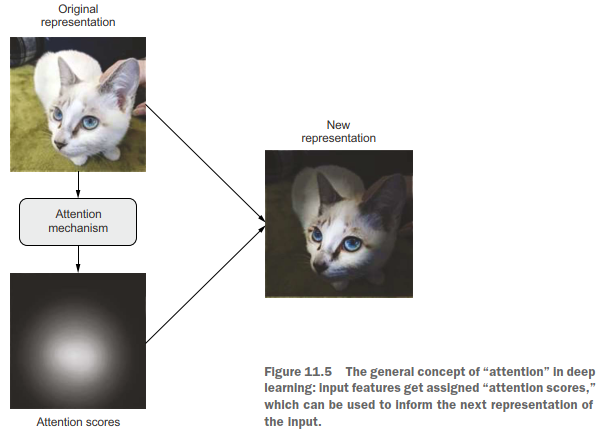

Crucially, this kind of attention mechanism can be used for more than just highlighting or erasing certain features. It can be used to make features context-aware. You’ve just learned about word embeddings—vector spaces that capture the “shape” of the semantic relationships between different words. In an embedding space, a single word has a fixed position—a fixed set of relationships with every other word in the space. But that’s not quite how language works: the meaning of a word is usually context-specific.

When you mark the date, you’re not talking about the same “date” as when you go on a date, nor is it the kind of date you’d buy at the market. When you say, “I’ll see you soon,” the meaning of the word “see” is subtly different from the “see” in “I’ll see this project to its end” or “I see what you mean.” And, of course, the meaning of pronouns like “he,” “it,” “in,” etc., is entirely sentence-specific and can even change multiple times within a single sentence. Clearly, a smart embedding space would provide a different vector representation
for a word depending on the other words surrounding it. That’s where self-attention comes in. The purpose of self-attention is to modulate the representation of a token by using the representations of related tokens in the sequence. This produces context-aware token representations. Consider an example sentence: “The train left the station on time.” Now, consider one word in the sentence: station. What kind of station are we talking about? Could it be a radio station? Maybe the International Space Station? Let’s figure it out algorithmically via self-attention.

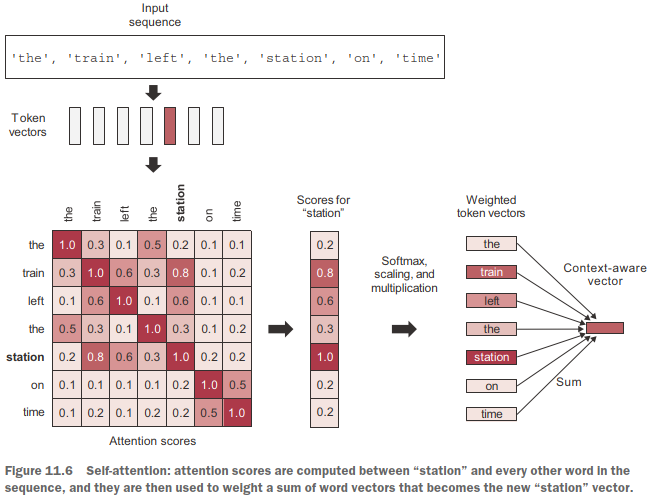

Step 1 is to compute relevancy scores between the vector for “station” and every other word in the sentence. These are our “attention scores.” We’re simply going to use the dot product between two word vectors as a measure of the strength of their relationship. It’s a very computationally efficient distance function, and it was already the standard way to relate two word embeddings to each other long before Transformers. In practice, these scores will also go through a scaling function and a softmax, but for now, that’s just an implementation detail.

Step 2 is to compute the sum of all word vectors in the sentence, weighted by our relevancy scores. Words closely related to “station” will contribute more to the sum (including the word “station” itself), while irrelevant words will contribute almost nothing. The resulting vector is our new representation for “station”: a representation that incorporates the surrounding context. In particular, it includes part of the “train” vector, clarifying that it is, in fact, a “train station.”

You’d repeat this process for every word in the sentence, producing a new
sequence of vectors encoding the sentence. Let’s see it in NumPy-like pseudocode:

### TODO 1

$$
\newcommand{\qv}{\mathbf{q}}
\newcommand{\kv}{\mathbf{k}}
\newcommand{\ov}{\mathbf{o}}
\newcommand{\vv}{\mathbf{v}}
$$


1. Compute the attention scores for $\alpha(\qv, \kv) = <\qv, \kv> / \sqrt{d}$.
    1. First the compute the dot product between pivot and other surrounding vectors for the numerator.
    1. Divide the `scores` with dot products with the numerator. Here $d$ is the dimensionality of input sequence, thus `input_sqeuence.shape[1]`.
    1. Apply softmax to the `scores`.
1. Compute the output $\ov = \sum_{i=1}^n a_i \vv_i$.
    1. Using `scores`, compute the weighted sum of `vectors`

In [3]:
def self_attention(input_sequence):
  output = np.zeros(shape=input_sequence.shape)
  for i, pivot_vector in enumerate(input_sequence):                       # Iterate over each token in the input sequence.
    scores = np.zeros(shape=(len(input_sequence),))
    for j, vector in enumerate(input_sequence):
      # TODO 1A - Compute dot product between pivot_vector and vector
      scores[j] = np.dot(pivot_vector, vector)

    # TODO 1B - Scale by sqrt(d) where d is the dimension of the vectors
    d = input_sequence.shape[1]  # Dimensionality of the vectors
    scores = scores / np.sqrt(d)

    # TODO 1C - Apply softmax to get attention weights
    scores = np.exp(scores) / np.sum(np.exp(scores))

    new_pivot_representation = np.zeros(shape=pivot_vector.shape)
    for j, vector in enumerate(input_sequence):
      # TODO 2A - Add the weighted vectors to form the new representation
      new_pivot_representation += scores[j] * vector

    output[i] = new_pivot_representation
  ################
  return output                                                           # That sum is our output.

Of course, in practice you’d use a vectorized implementation. Keras has a built-in layer to handle it: the MultiHeadAttention layer. Here’s how you would use it:

### TODO 2

1. Create a new variable `mha_layer` and initializes a Multi-Head Attention (MHA) layer using `layers.MultiHeadAttention` and pass two parameters `num_heads` as 4 and `key_dim` as 256
[Reference_LINK](https://www.tensorflow.org/api_docs/python/tf/keras/layers/MultiHeadAttention)

In [4]:
# TODO
mha_layer = layers.MultiHeadAttention(num_heads=4, key_dim=256)

# outputs = mha_layer(inputs, inputs, inputs)                                   # We need to define the input for this line to work.

### TODO2-1

* Why does the commented mha_layer have three identical inputs?

`Answer:`
- The three identical inputs represent the query, key, and value matrices for the attention mechanism. In self-attention, we want each position in the sequence to attend to all positions in the same sequence, so we use the same tensor for all three roles. This allows each token to gather information from all other tokens (including itself) in the sequence.

### Generalized Self-Attention: The query-key-value model

So far, we have only considered one input sequence. However, the Transformer architecture was originally developed for machine translation, where you have to deal with two input sequences: the source sequence you’re currently translating (such as “How’s the weather today?”), and the target sequence you’re converting it to (such as “¿Qué tiempo hace hoy?”). A Transformer is a sequence-to-sequence model: it was designed to convert one sequence into another. The self-attention mechanism as we’ve introduced it performs the following, schematically:

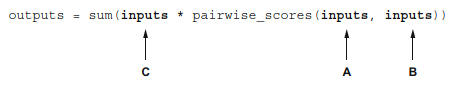

This means “for each token in inputs (A), compute how much the token is related to every token in inputs (B), and use these scores to weight a sum of tokens from inputs (C).” Crucially, there’s nothing that requires A, B, and C to refer to the same input sequence. In the general case, you could be doing this with three different sequences. We’ll call them “query,” “keys,” and “values.” The operation becomes “for each element in the query, compute how much the element is related to every key, and use these scores to weight a sum of values”:

image.png

This terminology comes from search engines and recommender systems. Imagine that you’re typing up a query to retrieve a photo from your collection—“dogs on the beach.” Internally, each of your pictures in the database is described by a set of keywords—“cat,” “dog,” “party,” etc. We’ll call those “keys.” The search engine will start by comparing your query to the keys in the database. “Dog” yields a match of 1, and “cat” yields a match of 0. It will then rank those keys by strength of match—relevance—and it will return the pictures associated with the top N matches, in order of relevance.

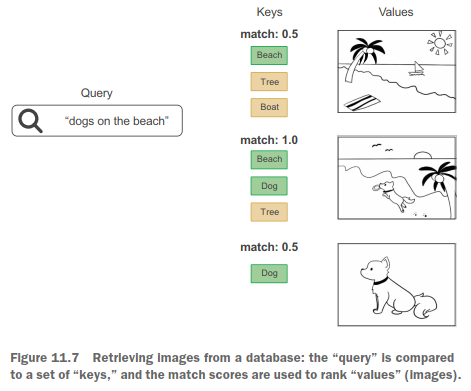

Conceptually, this is what Transformer-style attention is doing. You’ve got a reference sequence that describes something you’re looking for: the query. You’ve got a body of knowledge that you’re trying to extract information from: the values. Each value is assigned a key that describes the value in a format that can be readily compared to a query. You simply match the query to the keys. Then you return a weighted sum of values.

In practice, the keys and the values are often the same sequence. In machine translation, for instance, the query would be the target sequence, and the source sequence would play the roles of both keys and values: for each element of the target (like “tiempo”), you want to go back to the source (“How’s the weather today?”) and identify the different bits that are related to it (“tiempo” and “weather” should have a strong match). And naturally, if you’re just doing sequence classification, then query, keys, and values are all the same: you’re comparing a sequence to itself, to enrich each token with context from the whole sequence. That explains why we needed to pass inputs three times to our MultiHeadAttention layer. But why “multi-head” attention?

## Multi-head attention

“Multi-head attention” is an extra tweak to the self-attention mechanism, introduced in “Attention is all you need.” The “multi-head” moniker refers to the fact that the output space of the self-attention layer gets factored into a set of independent subspaces, learned separately: the initial query, key, and value are sent through three independent sets of dense projections, resulting in three separate vectors. Each vector is processed via neural attention, and the three outputs are concatenated back together into a single output sequence. Each such subspace is called a “head.” The full picture is shown below.


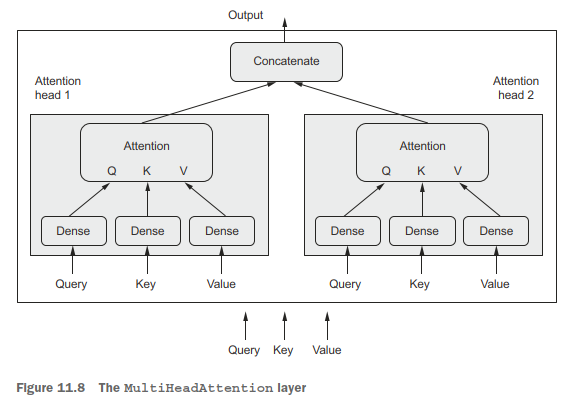

 ## The Transformer encoder

If adding extra dense projections is so useful, why don’t we also apply one or two to the output of the attention mechanism? Actually, that’s a great idea—let’s do that. And our model is starting to do a lot, so we might want to add residual connections to make sure we don’t destroy any valuable information. And there’s another thing: normalization layers are supposed to help gradients flow better during backpropagation. Let’s add those too.

That’s roughly the thought process that I imagine unfolded in the minds of the
inventors of the Transformer architecture at the time. Factoring outputs into multiple independent spaces, adding residual connections, adding normalization layers—all of these are standard architecture patterns that one would be wise to leverage in any complex model. Together, these bells and whistles form the Transformer encoder—one of two critical parts that make up the Transformer architecture.

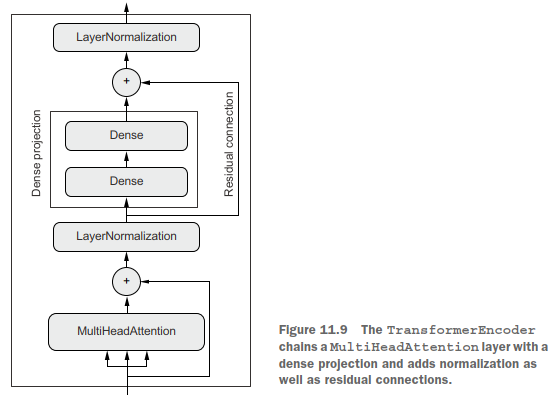

The original Transformer architecture consists of two parts: a Transformer encoder that processes the source sequence, and a Transformer decoder that uses the source sequence to generate a translated version.  

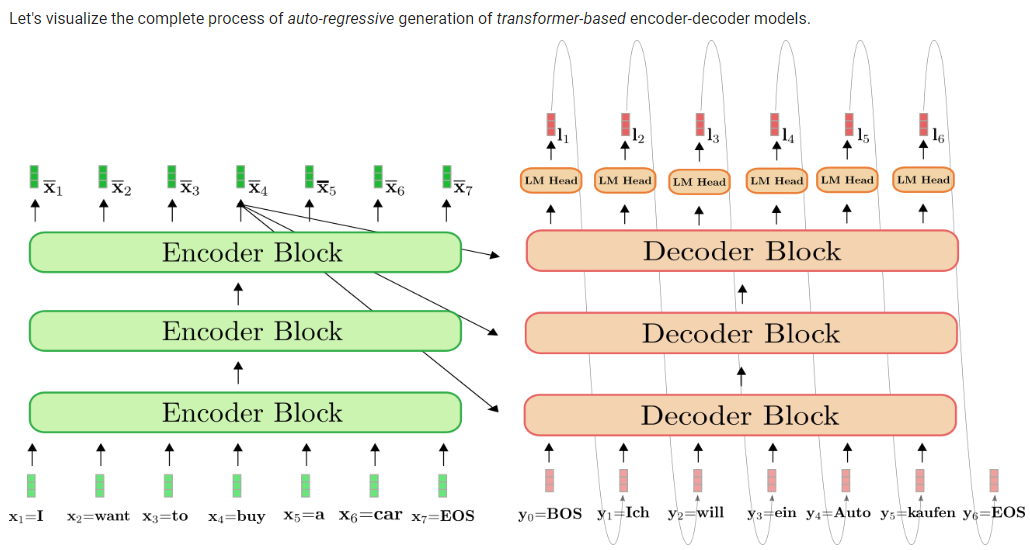

Crucially, the encoder part can be used for text classification—it’s a very generic module that ingests a sequence and learns to turn it into a more useful representation. Let’s implement a Transformer encoder and try it on the movie review sentiment
classification task.

## Using the Tranformer encoder on IMDB

Let us reuse IMDB dataset that we used last week.
### TODO 3
1. Declare a new variable as `max_tokens` set its value to 20000.
1. Declare a new variable as `max_len` set its value to 600.
1. Unpack the data into two pairs of arrays `(x_train_full, y_train_full)` for the training set and `(x_test, y_test)` for the test set. Then use the Keras IMDB dataset's load_data() method to load the dataset with `num_words` parameter set to `max_tokens`.
[Refer to this link for better understanding](https://www.tensorflow.org/api_docs/python/tf/keras/datasets/imdb/load_data)
1. In the `x_train, x_valid ` the training set consists of of all but the last 5000 reviews of `x_train_full` and validation set consists of the last 5000 reviews of `x_train_full`
    1. Hint: Use indexing method
1. Similarly `y_train, y_valid`  the training set consists of of all but the last 5000 reviews of `y_train_full` and validation set consists of the last 5000 reviews of `y_train_full`
1. Print the shape of x_train , y_train ,x_valid , y_valid , x_test and y_test

In [5]:
# TODO
max_tokens = 20000
max_len = 600
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=max_tokens)

x_train = x_train_full[:-5000]
x_valid = x_train_full[-5000:]
y_train = y_train_full[:-5000]
y_valid = y_train_full[-5000:]

print(f'Train Shape:, {x_train.shape, y_train.shape}')
print(f'Valid Shape:, {x_valid.shape, y_valid.shape}')
print(f'Test Shape:, {x_test.shape, y_test.shape}')

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train Shape:, ((20000,), (20000,))
Valid Shape:, ((5000,), (5000,))
Test Shape:, ((25000,), (25000,))


## Data Preparation

Run the following cell to prepare the data.

### TODO 4
1. Create a variable `x_train` using `keras.preprocessing.sequence.pad_sequences` pass two arguments `x_train` and `maxlen` as `max_len`
1. Create a variable `x_valid` using `keras.preprocessing.sequence.pad_sequences` pass two arguments `x_valid` and `maxlen` as `max_len`
1. Create a variable `x_test` using `keras.preprocessing.sequence.pad_sequences` pass two arguments `x_test` and `maxlen` as `max_len`

In [6]:
x_train = keras.preprocessing.sequence.pad_sequences(x_train, maxlen=max_len)
x_valid = keras.preprocessing.sequence.pad_sequences(x_valid, maxlen=max_len)
x_test = keras.preprocessing.sequence.pad_sequences(x_test, maxlen=max_len)

## Build the Transformer Encoder

Run the following cell to create the Transformer encoder.

## TODO 5
1. Create a class called `TransformerEncoder` that inherits from the `layers.Layer` class.
    1. Define the constructor for the TransformerEncoder class as `def __init__`. The constructor takes in three arguments `(self, embed_dim, dense_dim, num_heads, **kwargs)`.
        1. Call the constructor of the parent class (Layer) with the arguments passed to the constructor of TransformerEncoder using `super().__init__(**kwargs)`.
        1. Define three instance variables: `embed_dim`, `dense_dim`, and `num_heads` and assign with respect to each other.
        1. Create another instance `attention` using `layers.MultiHeadAttention` with additional parameters `num_heads` as `num_heads` and `key_dim` as `embed_dim`
        1. Create another instance `dense_proj` using `keras.Sequential` that consists of two dense layers one layer with both `dense_dim` with `relu` activation and other layer with only one argument `embed_dim`
        1. Create two instances of the LayerNormalization class `layers.LayerNormalization()` where first instance is stored in the instance variable `layernorm_1`, and the second instance is stored in the instance variable `layernorm_2`.
    1. defines the `call` method for the TransformerEncoder class. The method takes in three arguments `(self, inputs, mask=None)`
        1. Write a if statement if `mask` exists
            1. We want to expand the mask rank from 2D to 3D,  the `mask` is reshaped to have an extra dimension as `[:, tf.newaxis, :]`
        1. Create a varaible called `attention_output` in that apply MultiHeadAttention layer using `self.attention` where `inputs` argument is passed twice, third argument is `attention_mask` assigned to above `mask`.
        1. Create a varaible called `proj_input` .Apply layer normalization using `self.layernorm_1` with argumnets as sum of the `inputs` and the `attention output`
        1. Create a varaible called `proj_output` this line applies the `self.dense_proj` layer to the `proj_input`
        1. Now `return` the `self.layernorm_2` with argument as sum of `proj_input` and `proj_output`
    1. Finally Define a `get_config(self)`
        1. Create a variable called `config` ,call the get_config method of the base class using ` super().get_config()`
        1. update the config using `config.update()` Update dictionary with additional configuration options specific to this custom layer.Dictionary have the following arguments value of `"embed_dim"` set to `self.embed_dim`,` "num_heads"` set to `self.num_heads` , `"dense_dim"` set to `self.dense_dim`
        1. Finally `return` the `config`
        
      

In [20]:
class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim
        )

        self.dense_proj = keras.Sequential([
            layers.Dense(dense_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()

        # Add this to explicitly support masking
        self.supports_masking = True

    def build(self, input_shape):
        # This method is called when the model is first used
        self.built = True

    def call(self, inputs, mask=None):                                # Computation goes in call().
        if mask is not None:                                          # The mask that will be generated by the Embedding layer will be 2D, but
            # Properly format the mask for attention                  # the attention layer expects to be 3D or 4D, so we expand its rank.
            mask = mask[:, tf.newaxis, :]

        attention_output = self.attention(
            inputs, inputs,
            attention_mask=mask
        )

        proj_input = self.layernorm_1(inputs + attention_output)

        proj_output = self.dense_proj(proj_input)

        return self.layernorm_2(proj_input + proj_output)

    def get_config(self):                                             # Implement serialization so we can save the model.
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "dense_dim": self.dense_dim,
        })
        return config

## Using the Transformer encoder for text classification

Now that we’ve implemented our TransformerEncoder, we can use it to assemble a
text-classification model.

Run the next cell to train the model using the Transformer encoder.

### TODO 6
1. create a new variable `vocab_size` and set the dimensionality to `20000`
1. create a new variable `embed_dim` and set the dimensionality of the word embeddings to `256`.
1. Also set `num_heads` as `2` and `dense_dim` as `32`

1. Create a variable called `inputs` and define the input shape of the model Using `keras.Input` with shape of `shape=(None,)` and `dtype` as "int64".
1. Create a variable called `x` which has `layers.Embedding` and take parameters as `vocab_size`,`embed_dim` .which now receives input as previous output `inputs`
1. Make a variable called `x` , which has `TransformerEncoder` and it should take parameters `embed_dim`, `dense_dim`, `num_heads` and take input as previous output `x`
1. Now apply max pooling using `layers.GlobalMaxPooling1D()` on `x`
1. Apply the dropout regularization to the output of the previous pooling layer `x`.Sets dropout rate to `0.5`.
1. create a `outputs` variable having Another Dense() layer is created with a single neuron and a `sigmoid` activation function. This layer is applied to the output of the previous layer `x`.
1.  creat a `model` variable using `keras.Model` It takes the input tensor `inputs` and the output tensor `outputs` as arguments.
1. Finally Lets compile the model , Using `model.compile`, prepare your model to have "rmsprop" as an `optimizer`, have a `loss` function to be "binary_crossentropy" also it should take `metrics` as "accuracy".
1. print the `model` summary.

In [8]:
# TODO 6
vocab_size = 20000
embed_dim = 256
num_heads = 2
dense_dim = 32

inputs = keras.Input(shape=(None,), dtype="int64")

x = layers.Embedding(vocab_size, embed_dim)(inputs)
x = TransformerEncoder(embed_dim, dense_dim, num_heads)(x)
x = layers.GlobalMaxPooling1D()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 256)      │     5,120,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder             │ (None, None, 256)      │       543,776 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 256)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,664,033 (21.61 MB)

 Trainable params: 5,664,033 (21.61 MB)

 Non-trainable params: 0 (0.00 B)

Let’s train it.

### TODO 7
1. Create a variable as `callbacks` and using `keras.callbacks.ModelCheckpoint` and `save the best` model weights.
  * Save weights in .keras format in filepath
1. Create a variable called `history` , Using `model.fit`, train the `x_train`, `y_train` and `validation_data`   as `(x_valid, y_valid)` with 10 `epochs`, and `callbacks` as callbacks``
1. Plot the `history` using `plot_learning`.

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 102s 123ms/step - accuracy: 0.5677 - loss: 0.8276 - val_accuracy: 0.7916 - val_loss: 0.4458
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 66s 105ms/step - accuracy: 0.8263 - loss: 0.3898 - val_accuracy: 0.8538 - val_loss: 0.3509
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 66s 106ms/step - accuracy: 0.8490 - loss: 0.3496 - val_accuracy: 0.8604 - val_loss: 0.3320
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 66s 106ms/step - accuracy: 0.8715 - loss: 0.3055 - val_accuracy: 0.8682 - val_loss: 0.3168
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 66s 106ms/step - accuracy: 0.8776 - loss: 0.2911 - val_accuracy: 0.8628 - val_loss: 0.3247
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 107ms/step - accuracy: 0.8891 - loss: 0.2651 - val_accuracy: 0.8742 - val_loss: 0.3125
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 108ms/step - accuracy: 0.9078 - loss: 0.2356 - val_accuracy: 0.8680 - val_loss: 0.3155
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 108ms/step - accuracy: 0.9109 - loss: 

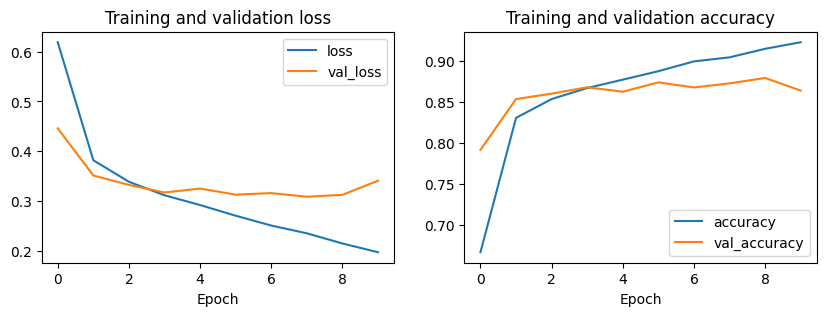

In [9]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="best_transformer_model.keras",
        save_best_only=True,
        monitor="val_accuracy"
    )
]

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_valid, y_valid),
    epochs=10,
    callbacks=callbacks
)


plot_learning(history)

### TODO 8
1. Load the model using `keras.models.load_model()` and add additional `custom_objects` which should be equal to a dictionary `"TransformerEncoder"`: `TransformerEncoder` in a new variable called `model`.
2. Evaluate your model using `model.evaluate` on `x_test`,`y_test` it should returns the test loss and accuracy of the model

In [13]:
model = keras.models.load_model(
    "best_transformer_model.keras",
    custom_objects={"TransformerEncoder": TransformerEncoder}
)

model.evaluate(x_test, y_test)


782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8685 - loss: 0.3210


[0.32432353496551514, 0.8666800260543823]

It gets to 88% test accuracy.

At this point, you should start to feel a bit uneasy. Something’s off here. Can you tell what it is? I started off by highlighting the importance of word order. I said that Transformer was a sequence-processing architecture, originally developed for machine translation. And yet . . . the Transformer encoder you just saw in action wasn’t a sequence model at all. Did you
notice? It’s composed of dense layers that process sequence tokens independently
from each other, and an attention layer that looks at the tokens as a set. You could change the order of the tokens in a sequence, and you’d get the exact same pairwise attention scores and the exact same context-aware representations. If you were to completely scramble the words in every movie review, the model wouldn’t notice, and you’d still get the exact same accuracy. Self-attention is a set-processing mechanism, focused on the relationships between pairs of sequence elements—it’s blind to whether these elements occur at the beginning, at the end, or in the middle of a sequence. So why do we say that Transformer is a sequence model? And how could it possibly be good for machine translation if it doesn’t look at word order?

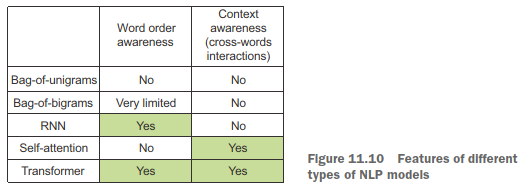

I hinted at the solution earlier: I mentioned in passing that Transformer was a hybrid approach that is technically order-agnostic, but that manually injects order information in the representations it processes. This is the missing ingredient! It’s called positional encoding. Let’s take a look.

## Using Positional Encoding to Re-inject Order Information

The idea behind positional encoding is very simple: to give the model access to word-order information, we’re going to add the word’s position in the sentence to each word embedding. Our input word embeddings will have two components: the usual word vector, which represents the word independently of any specific context, and a position vector, which represents the position of the word in the current sentence. Hopefully, the model will then figure out how to best leverage this additional information.

The simplest scheme you could come up with would be to concatenate the word’s
position to its embedding vector. You’d add a “position” axis to the vector and fill it with 0 for the first word in the sequence, 1 for the second, and so on.
That may not be ideal, however, because the positions can potentially be very large integers, which will disrupt the range of values in the embedding vector. As you know, neural networks don’t like very large input values, or discrete input distributions. The original “Attention is all you need” paper used an interesting trick to encode word positions: it added to the word embeddings a vector containing values in the range [-1, 1] that varied cyclically depending on the position (it used cosine functions to achieve this). This trick offers a way to uniquely characterize any integer in a large range via a vector of small values.

It’s clever, but it’s not what we’re going to use in our case. We’ll do something simpler and more effective: we’ll learn position-embedding vectors the same way we learn to embed word indices. We’ll then proceed to add our position embeddings to the corresponding word embeddings, to obtain a position-aware word embedding. This technique is called “positional embedding.”
Let’s implement it.

### TODO 9
1. Create a `class` `PositionalEmbedding` The layer inherits from the `layers.Layer`.
    1. Define the constructor for the TransformerEncoder class as `def __init__`. The constructor takes in three arguments `(self, sequence_length, input_dim, output_dim, **kwargss)`.
        1. Call the initializer of the base class with the arguments passed to the constructor using `super().__init__(**kwargs)`.
        1. Create  instance `token_embeddings` using `layers.Embedding` with additional parameters `input_dim` as `input_dim` and `output_dim` as `output_dim`
        1. Create  another instance `position_embeddings` using `layers.Embedding` with additional parameters `input_dim` as `sequence_length` and `output_dim` as `output_dim`
        1. Define three instance variables: `sequence_length`, `input_dim`, and `output_dim` and assign with respect to each other.
    1. Define the `call` method for the above class. The method takes in two arguments `(self, inputs)`
        1. Create a variable called `length` and assign it to length of the input tensor along the last dimension using `tf.shape` on `inputs` along the last dimesion`[-1]`.
        1. Create a variable called `positions`.Generate a tensor containing the positional indices of the input tokensgenerates a tensor containing the positional indices of the input tokens using `tf.range` by passing three arguments `start` as `0` , `limit` as `length`, `delta` as `1`.            
        1. Create a varaible called `embedded_tokens` in that apply token_embeddings on input using `self.token_embeddings` on `inputs`
        1. Create a varaible called `embedded_positions` in that apply position_embeddings on positions using `self.position_embeddings` on `positions`
        1.  Now `return` the sum of `embedded_tokens` and `embedded_positions`.
    1. Define the `compute_mask` method and pass three arguments `(self, inputs, mask=None)`
        1. Now `return` the `tf.math.not_equal` function and pass two arguments `inputs`, `0`
    1. Finally Define a `get_config(self)`
        1. Create a variable called `config` ,call the get_config method of the base class using ` super().get_config()`
        1. update the config using `config.update()` Update dictionary with additional configuration options specific to this custom layer.Dictionary have the following arguments value of `"output_dim"` set to `self.output_dim`,` "sequence_length"` set to `self.sequence_length` , `"input_dim"` set to `self.input_dim`
        1. Finally `return` the `config`
        
      

In [30]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, input_dim, output_dim, **kwargs):                   # A downside of position embeddings is that the sequence length needs to be known in advance.
        super().__init__(**kwargs)
        self.token_embeddings = layers.Embedding(
            input_dim=input_dim,
            output_dim=output_dim
        )

        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length,
            output_dim=output_dim
        )

        self.sequence_length = sequence_length
        self.input_dim = input_dim
        self.output_dim = output_dim

    def build(self, input_shape):
        # This method is called when the model is first used
        # It ensures that all weights are created before the first forward pass
        self.built = True

    def call(self, inputs):
        length = tf.shape(inputs)[1]

        positions = tf.range(start=0, limit=length, delta=1)

        embedded_tokens = self.token_embeddings(inputs)
        positions = tf.expand_dims(positions, axis=0)
        embedded_positions = self.position_embeddings(positions)

        return embedded_tokens + embedded_positions

    def compute_mask(self, inputs, mask=None):                                              # Like the Embedding layer, this layer should be able to generate a mask so we can ignore padding 0s in the inputs.
                                                                                            # The compute_mask method will called automatically by the framework, and the mask will get propagated to the next layer.
        return keras.ops.not_equal(inputs, 0)

    def get_config(self):
        config = super().get_config()
        config.update({
            "output_dim": self.output_dim,
            "sequence_length": self.sequence_length,
            "input_dim": self.input_dim,
        })
        return config

You would use this PositionEmbedding layer just like a regular Embedding layer. Let’s see it in action!

### Putting it all together: A text-classification Transformer

All you have to do to start taking word order into account is swap the old Embedding
layer with our position-aware version.

### TODO 10

1. Copy the entire `TODO 6 ` but with one change in the `PositionalEmbedding` layer, just add one more additional argument `sequence_length` , which is `600`.

In [26]:
vocab_size = 20000
embed_dim = 256
num_heads = 2
dense_dim = 32

inputs = keras.Input(shape=(None,), dtype="int64")

x = PositionalEmbedding(sequence_length=600, input_dim=vocab_size, output_dim=embed_dim)(inputs)
x = TransformerEncoder(embed_dim, dense_dim, num_heads)(x)
x = layers.GlobalMaxPooling1D()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:938: UserWarning: Layer 'global_max_pooling1d_3' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 256) │  5,273,600 │ input_layer_13[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, None)      │          0 │ input_layer_13[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 256) │    543,776 │ positional_embed… │
│ (TransformerEncode… │                   │            │ not_equal_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 256)       │          0 │ transformer_enco… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 256)       │          0 │ global_max_pooli… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 1)         │        257 │ dropout_11[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,817,633 (22.19 MB)

 Trainable params: 5,817,633 (22.19 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 48s 56ms/step - accuracy: 0.6393 - loss: 0.7296 - val_accuracy: 0.8674 - val_loss: 0.3142
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 39s 63ms/step - accuracy: 0.8649 - loss: 0.3213 - val_accuracy: 0.8750 - val_loss: 0.2940
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 43s 69ms/step - accuracy: 0.9023 - loss: 0.2486 - val_accuracy: 0.8722 - val_loss: 0.3012
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 42s 68ms/step - accuracy: 0.9212 - loss: 0.2010 - val_accuracy: 0.8904 - val_loss: 0.2669
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 46s 74ms/step - accuracy: 0.9360 - loss: 0.1705 - val_accuracy: 0.8766 - val_loss: 0.3441
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 80ms/step - accuracy: 0.9494 - loss: 0.1406 - val_accuracy: 0.8922 - val_loss: 0.2818
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 66ms/step - accuracy: 0.9605 - loss: 0.1063 - val_accuracy: 0.8908 - val_loss: 0.3074
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.9709 - loss: 0.0830 - 

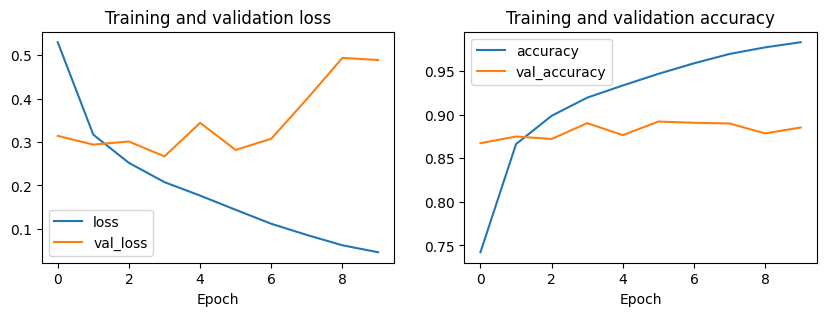

In [27]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="best_transformer_positional_model.keras",
        save_best_only=True,
        monitor="val_accuracy"
    )
]

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_valid, y_valid),
    epochs=10,
    callbacks=callbacks
)


plot_learning(history)

### TODO 11
1. Load the model using `keras.models.load_model()` and add aditional `custom_objects` which should be equal to a dictionary `"TransformerEncoder"`: `TransformerEncoder` and  `"PositionalEmbedding"`: `PositionalEmbedding` in a new variable called `model`.
2. Evaluate your model using `model.evaluate` on `x_test` and `y_test` it should returns the test loss and accuracy of the model

In [31]:
model = keras.models.load_model(
    "best_transformer_positional_model.keras",
    custom_objects={"TransformerEncoder": TransformerEncoder,"PositionalEmbedding": PositionalEmbedding}
)

model.evaluate(x_test, y_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8791 - loss: 0.2996


[0.30144280195236206, 0.8786399960517883]

We get to 88.1% test accuracy, a solid improvement that clearly demonstrates the
value of word order information for text classification. This is our best sequence model so far! However, it’s still one notch below the bag-of-words approach.

### When to use sequence models over bag-of-words models?

You may sometimes hear that bag-of-words methods are outdated, and that Transformer-based sequence models are the way to go, no matter what task or dataset you’re looking at. This is definitely not the case: a small stack of Dense layers on top of a bag-of-bigrams remains a perfectly valid and relevant approach in many cases. In fact, among the various techniques that we’ve tried on the IMDB dataset, the best performing so far was the bag-of-bigrams!

It turns out that when approaching a new text-classification task, you should pay close attention to the ratio between the number of samples in your training data and the mean number of words per sample. If that ratio is small—less than 1,500—then the bag-of-bigrams model will perform better (and as a bonus, it will be much faster to train and to iterate on too). If that ratio is higher than 1,500, then you should go with a sequence model. In other words, sequence models work best when lots of training data is available and when each sample is relatively short.

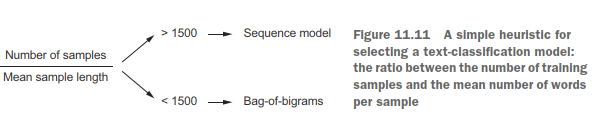

So if you’re classifying 1,000-word long documents, and you have 100,000 of them (a ratio of 100), you should go with a bigram model. If you’re classifying tweets that are 40 words long on average, and you have 50,000 of them (a ratio of 1,250), you should also go with a bigram model. But if you increase your dataset size to 500,000 tweets (a ratio of 12,500), go with a Transformer encoder. What about the IMDB movie review classification task? We had 20,000 training samples and an average word count of 233, so our rule of thumb points toward a bigram model, which confirms what we found in practice.

This intuitively makes sense: the input of a sequence model represents a richer
and more complex space, and thus it takes more data to map out that space; mean-
while, a plain set of terms is a space so simple that you can train a logistic regression on top using just a few hundreds or thousands of samples. In addition, the shorter a sample is, the less the model can afford to discard any of the information it contains— in particular, word order becomes more important, and discarding it can create ambiguity. The sentences “this movie is the bomb” and “this movie was a bomb” have very close unigram representations, which could confuse a bag-of-words model, but a sequence model could tell which one is negative and which one is positive. With a longer sample, word statistics would become more reliable and the topic or sentiment would be more apparent from the word histogram alone.